# Models for transient, confined flow in semi-infinite aquifers

In [1]:
# GEOSCI-627 Class 14

#Import needed modules
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

from scipy.integrate import quad

# The Theis Solution

The Thiem solution has a number of drawbacks including that you may have to wait a *very* long time for steady-state drawdown conditions to be reached. You must also have wells at multiple observation distances where you can measure drawdowns. Similarly, because you are only measuring heads at steady state, your results are not dependent on (and thus you cannot estimate) aquifer storativity.

The Theis solution requires only one observation well, and similarly allows you to use transient data to estimate both aquifer Transmissivity and Storativity. The aquifer is still assumed to be confined, uniform thickness, homogeneous, and of semi-infinite extent.

In [2]:
def WellFunc(u):
    Wu = sp.special.exp1(u)
    return Wu

def Theis_sol(Q, T, S, r, t, h_init):
    # Integral term for the Hantush well function
    u = (S*r**2)/(4*T*t)
    Wu = WellFunc(u)
    #the np.where function is used to return a drawdown of 0 before t = 0
    h = np.where(u > 0, -Q/(4*np.pi*T)*Wu + h_init, h_init)
    return h


Below we will generate some field data (inherently assuming that the Theis solution is representative of our aquifer). First, we generate a drawdown curve showing what the head and drawdown data from a single point in space would look like. Second, we show the "cone of depression" that would be seen if you could view the head in the aquifer at all points in space.

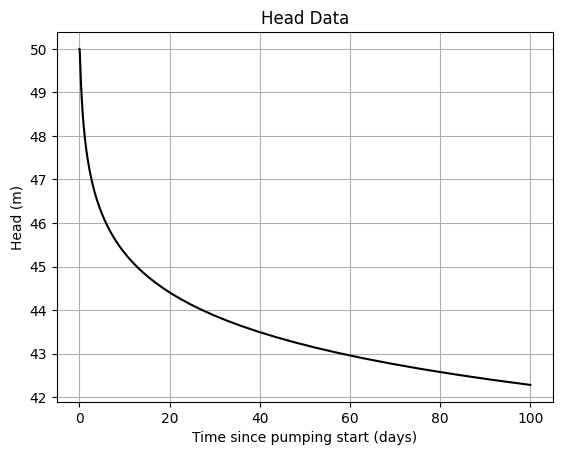

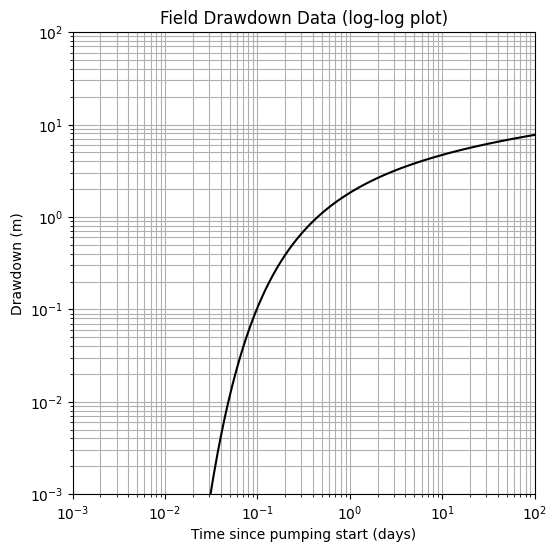

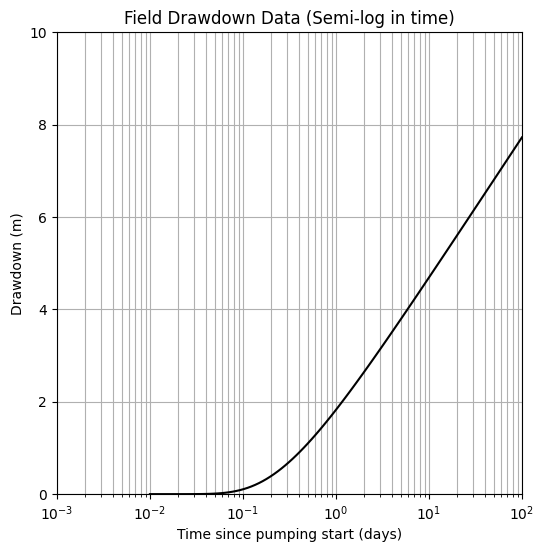

In [3]:
# Transient plot - drawdown at a given well location

#Actual field testing parameters - to generate synthetic field data
#EDIT: Uncomment this to show startup, then initial drawdown
#t_field = np.linspace(-20,100,700) #days
#EDIT: Uncomment this to plot only points after pumping starts, with high sampling near the pumping starting
t_field = np.logspace(-2,2,100) #days
r_field = 100 # m
Q_field = 25 # m^3/day
h_init = 50 # m

#True parameter values
K = 0.15 # m/day
Ss = 1e-5 # 1/m
b = 10 #m
T = K*b
S = Ss*b

h_field = Theis_sol(Q_field, T, S, r_field, t_field, h_init)
dd_field = h_init - h_field
#EDIT Uncomment this line to look at the effect of noisy data (5 mm standard deviation) on plots
#dd_field = h_init - h_field + 0.005*np.random.randn(100)

fig, ax = plt.subplots()
ax.plot(t_field,h_field, 'k')
ax.grid(visible='yes')
ax.set_xlabel('Time since pumping start (days)')
ax.set_ylabel('Head (m)')
ax.set_title('Head Data')
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(t_field,dd_field, 'k')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_aspect('equal')
ax.set_xbound((0.001, 100))
ax.set_ybound((0.001, 100))
ax.grid(visible='yes',which='both')
ax.set_xlabel('Time since pumping start (days)')
ax.set_ylabel('Drawdown (m)')
ax.set_title('Field Drawdown Data (log-log plot)')
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(t_field,dd_field, 'k')
ax.set_xscale('log')
ax.set_yscale('linear')
ax.set_xbound((0.001, 100))
ax.set_ybound((0, 10))
#ax.set_aspect('equal')
ax.grid(visible='yes',which='both')
ax.set_xlabel('Time since pumping start (days)')
ax.set_ylabel('Drawdown (m)')
ax.set_title('Field Drawdown Data (Semi-log in time)')
plt.show()

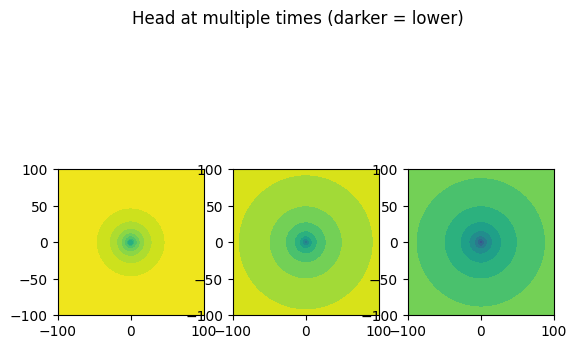

In [4]:
# Cone of Depression plots:
#Example plots to show what drawdown looks like surrounding a well at multiple points in time

x_coords = np.linspace(-100,100,50)
y_coords = np.linspace(-100,100,50)
xc,yc = np.meshgrid(x_coords,y_coords)
rc = (xc**2 + yc**2)**(1/2)
t_trials = [0.1, 1, 10]

h_theis_map1 = Theis_sol(Q_field, T, S, rc, t_trials[0], h_init)
h_theis_map2 = Theis_sol(Q_field, T, S, rc, t_trials[1], h_init)
h_theis_map3 = Theis_sol(Q_field, T, S, rc, t_trials[2], h_init)

fig, ax = plt.subplots(ncols=3)
cp = ax[0].contourf(xc, yc, h_theis_map1,vmin=30.0, vmax=50.0)
ax[0].set_aspect('equal','box')
cp = ax[1].contourf(xc, yc, h_theis_map2,vmin=30.0, vmax=50.0)
ax[1].set_aspect('equal','box')
cp = ax[2].contourf(xc, yc, h_theis_map3,vmin=30.0, vmax=50.0)
ax[2].set_aspect('equal','box')
fig.suptitle('Head at multiple times (darker = lower)')
plt.show()

Using the field data generated above, we now show how to use the Theis "type curve" to estimate aquifer properties. The Theis Type Curve is produced below by plotting 1/u vs. W(u) on a log-log plot at the same scale as your field data. 

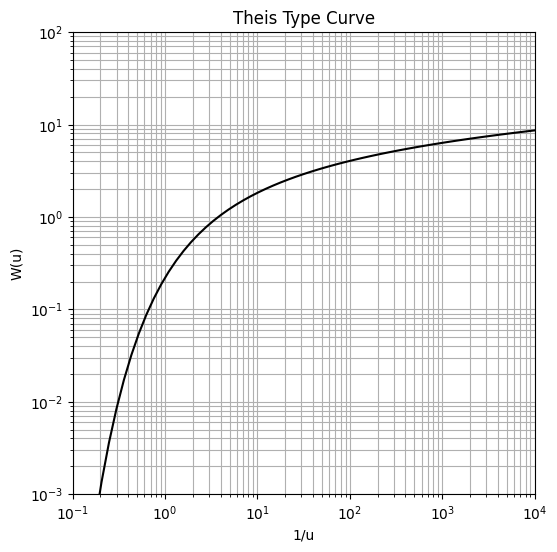

In [5]:
#The Theis "Type Curve" can be matched to a similar log-log plot of field data to
#Estimate both T and S, by determining horizontal and vertical offsets 
#of the well function vs 1/u

u = np.logspace(-4,4,100)
Wu = WellFunc(u)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(1/u,Wu, 'k')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_aspect('equal')
ax.grid(visible='yes',which='both')
ax.set_xbound((0.1, 10000))
ax.set_ybound((0.001, 100))
ax.set_xlabel('1/u')
ax.set_ylabel('W(u)')
ax.set_title('Theis Type Curve')
plt.show()

## Questions to Try

1. What do you obtain for the required horizontal and vertical offset of the type curve?
2. Based on this result, what estimate of aquifer transmissivity and storativity do you get? Is it comparable to the "true" value (i.e., the value through which we generated the data)?


In [6]:
# Using the Theis curve-matching approach, find the horizontal offset and vertical offset
# required to match the field data

# EDIT: Enter your horizontal and vertical offsets here
offset_v = 1.5
offset_h = 0.2

T_theismatch_est = Q_field/(4*np.pi*offset_v)
S_theismatch_est = offset_h*4*T_theismatch_est/(r_field**2)

print('Parameters estimated through Theis curve match:')
print('T = ', T_theismatch_est)
print('S = ', S_theismatch_est)


Parameters estimated through Theis curve match:
T =  1.3262911924324612
S =  0.00010610329539459691


## The Cooper-Jacob Approximate Solution

The Theis curve matching approach works very well when "early time" data is high-quality. However, early data is often contaminated by a high noise-to-drawdown ratio, and by variability in pump operations during early setup of pumping tests.

Based on the insight that late-time data is approximately linear when plotted on log-time vs. drawdown plots, the Cooper-Jacob approximate solution was derived. General guidance is that when u is "small" (a benchmark of ~0.01 is often used), the Theis and Cooper-Jacob solution should be approximately the same. Investigate the plots below as well as the estimated critical time at which u is "small" to observe the behavior.

In [7]:
def CooperJacob_dd_soln(Q, T, S, r, t):
    # Integral term for the Hantush well function
    u = (S*r**2)/(4*T*t)
    #the np.where function is used to return a drawdown of 0 before t = 0
    dd = np.where(u > 0, Q/(4*np.pi*T)*(-0.577216-np.log(u)), 0)
    return dd

t_crit is estimated as  0.16666666666666669 days


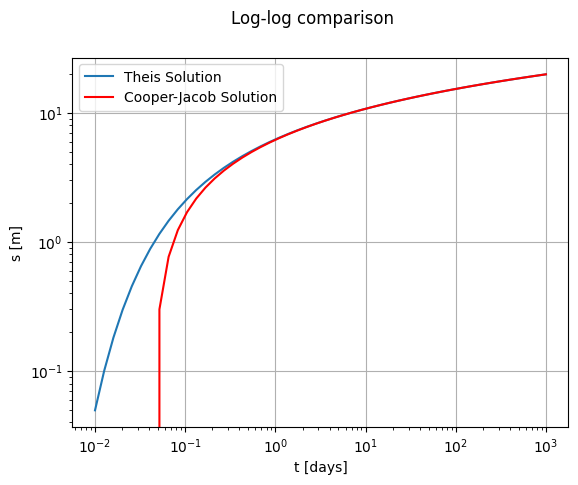

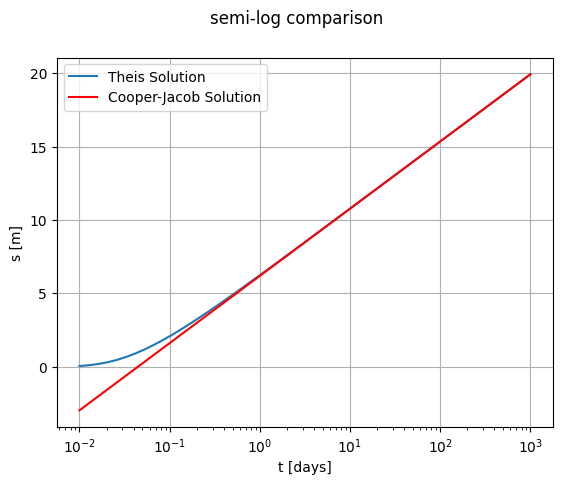

In [8]:
# Investigating the Cooper-Jacob approximate solution relative to the exact Theis solution

#Trial parameters for plotting the Theis vs. Cooper Jacob results
#EDIT: Feel free to change these parameters to investigate the effect on 
Q_test = 25 # m^3/day 
T_test = 1 # m^2/day
S_test = 0.001 # [-]
h_init_test = 30 # m
r_test = 10

t_test = np.logspace(-2,3,50)

#Metric for when curves should match
#when u is small (~0.01), fit should be excellent
#Since u = r^2*S/(4*T*t), we can solve for t
t_crit = (r_test**2*S)/(4*T*0.01)
print('t_crit is estimated as ', t_crit, 'days')

dd_theis = h_init_test - Theis_sol(Q_test,T_test,S_test,r_test,t_test,h_init_test)
dd_cj = CooperJacob_dd_soln(Q_test,T_test,S_test,r_test,t_test)

fig, ax = plt.subplots()
fig.suptitle('Log-log comparison')
ax.plot(t_test,dd_theis, label='Theis Solution')
ax.plot(t_test,dd_cj, 'r', label='Cooper-Jacob Solution')
ax.set_xscale('log')
ax.set_yscale('log')
# ax.set_aspect('equal')
ax.grid(visible='yes')
ax.set_xlabel('t [days]')
ax.set_ylabel('s [m]')
plt.legend()
plt.show()

fig, ax = plt.subplots()
fig.suptitle('semi-log comparison')
ax.plot(t_test,dd_theis, label='Theis Solution')
ax.plot(t_test,dd_cj, 'r', label='Cooper-Jacob Solution')
ax.set_xscale('log')
ax.set_yscale('linear')
# ax.set_aspect('equal')
ax.grid(visible='yes')
ax.set_xlabel('t [days]')
ax.set_ylabel('s [m]')
plt.legend()
plt.show()


## Questions to Try

1. What do you obtain for the field data's drawdown slope per log-time cycle, and the theoretical zero drawdown time?
2. Based on this result, what estimate of aquifer transmissivity and storativity do you get? Is it comparable to the "true" value (i.e., the value through which we generated the data)?

In [9]:
# Using the field data plot, find the change in drawdown per log-cycle on the semi-logarithmic
# plot, as well as the estimated "theoretical zero drawdown" intercept.

# EDIT: Enter your measurements from the log-linear plot here
deltas_perlog10t = 8
ddzero_tint = 1

T_cj_est = 2.3*Q_field/(4*np.pi*deltas_perlog10t)
S_cj_est = 2.25*T_cj_est*ddzero_tint/(r_field**2)

print('Parameters estimated through Cooper-Jacob curve match:')
print('T = ', T_cj_est)
print('S = ', S_cj_est)



Parameters estimated through Cooper-Jacob curve match:
T =  0.5719630767364988
S =  0.00012869169226571223
